# Week 1: Why compute in economics?

[Open in Colab](https://colab.research.google.com/github/WSU-EconS431/site/blob/main/weeks/week01.ipynb) · [View on GitHub](https://github.com/WSU-EconS431/site/blob/main/weeks/week01.ipynb)

Most models in your economics courses so far could be solved with pencil and paper. This course is about the ones that can't, or that are much easier to understand once a computer does the algebra. We start with a model you already know, a competitive market, and let Python solve it, draw it, and change it.

## A market in a few lines

Linear demand $Q_d = a - bP$ and supply $Q_s = c + dP$. Setting $Q_d = Q_s$ gives $P^* = (a - c)/(b + d)$.

In [1]:
a, b = 100, 2   # demand intercept and slope
c, d = 10, 1    # supply intercept and slope

p_star = (a - c) / (b + d)
q_star = a - b * p_star
print(f"Equilibrium price {p_star:.2f}, quantity {q_star:.2f}")

Equilibrium price 30.00, quantity 40.00


## Drawing it

A computer makes the familiar diagram from the numbers themselves.

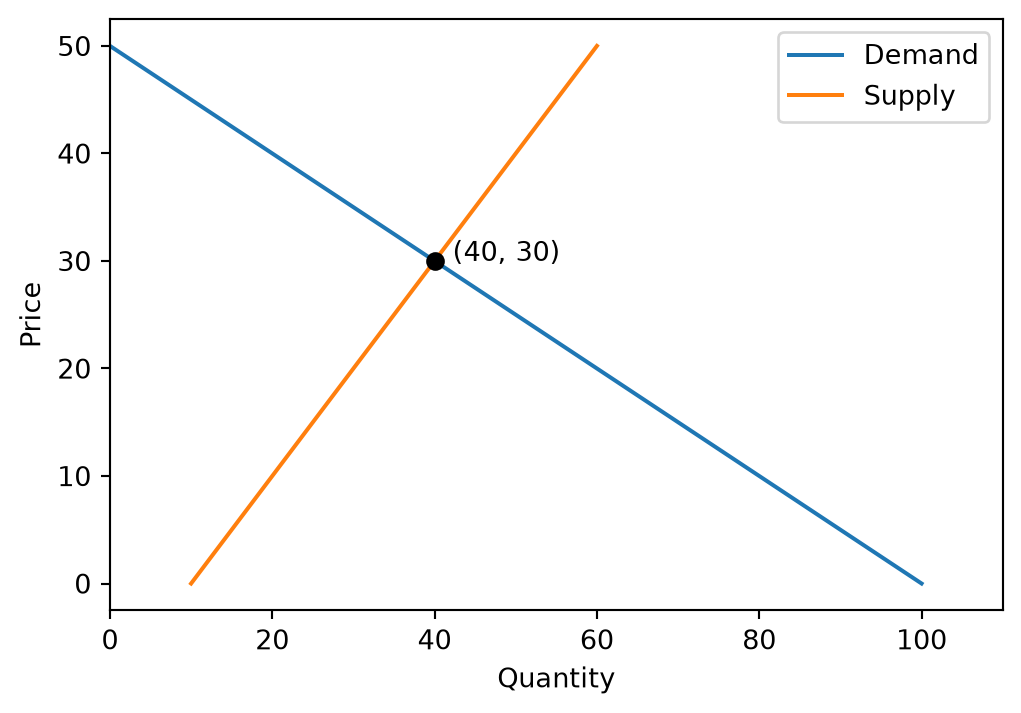

In [2]:
import numpy as np
import matplotlib.pyplot as plt

p = np.linspace(0, 50, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(a - b * p, p, label="Demand")
ax.plot(c + d * p, p, label="Supply")
ax.plot(q_star, p_star, "o", color="black")
ax.annotate(f"  ({q_star:.0f}, {p_star:.0f})", (q_star, p_star))
ax.set_xlabel("Quantity")
ax.set_ylabel("Price")
ax.set_xlim(0, 110)
ax.legend()
plt.show()

## Changing it

What happens to the equilibrium as demand grows? Instead of redoing the algebra, let the computer repeat it for many values of $a$.

In [3]:
import pandas as pd

rows = []
for a_new in [80, 90, 100, 110, 120]:
    p_new = (a_new - c) / (b + d)
    rows.append({"demand intercept a": a_new, "price": p_new, "quantity": a_new - b * p_new})

pd.DataFrame(rows).round(2)

,demand intercept a,price,quantity
0,80,23.33,33.33
1,90,26.67,36.67
2,100,30.00,40.00
3,110,33.33,43.33
4,120,36.67,46.67


## Writing it up

Code computes an answer; the text around it says what the answer means. A notebook has a cell type for each job. **Code cells** run Python. **Markdown cells** hold formatted text: headings, lists, tables, and equations written in **LaTeX**, the notation economists, journals, and textbooks use for math. Every problem set asks you to explain results in Markdown cells, and that text is what gets read and graded.

**Markdown cells in your codespace**

- Add one with the **+ Markdown** button that appears when you hover between cells.
- To switch a cell's type, click to the left of it (so it's selected but you aren't typing in it), then press **M** for Markdown or **Y** for code.
- Press **Shift+Enter** to render a Markdown cell. Double-click it to edit again.

### Markdown

You type plain text with a few symbols, and it renders as formatted text:

```markdown
**Result:** with linear demand and supply, the market clears at a price of
**30** and a quantity of **40**.

What the model leaves out:

- taxes and subsidies
- market power (*Week 11*)

[If Python says a package is missing (`ModuleNotFoundError`), see the Setup FAQ.](https://wsu-econs431.github.io/site/setup-faq.html#missing-package)
```

renders as:

> **Result:** with linear demand and supply, the market clears at a price of
> **30** and a quantity of **40**.
>
> What the model leaves out:
>
> - taxes and subsidies
> - market power (*Week 11*)
>
> [If Python says a package is missing (`ModuleNotFoundError`), see the Setup FAQ.](https://wsu-econs431.github.io/site/setup-faq.html#missing-package)

| You type | You get |
|---|---|
| `# Title`, `## Section`, `### Subsection` | headings, largest to smallest |
| `*italic*` and `**bold**` | *italic* and **bold** |
| `- item` or `1. item`, one per line | a bulleted or numbered list |
| `[QuantEcon](https://quantecon.org)` | a link: [QuantEcon](https://quantecon.org) |
| `` `p_star` `` | code: `p_star` |
| `![Market diagram](market.png)` | an image saved next to the notebook (Week 3 shows how to save one) |
| a blank line | a new paragraph |

**Blank lines matter.** Put one before every list, heading, table, and display equation. Without it, Markdown can run them into the paragraph above. A single line break inside a paragraph is ignored, so you can wrap long lines however you like.

**Tables** use pipes and dashes. A colon on the right of the dashes right-aligns a column, which suits numbers:

```markdown
| Demand intercept $a$ | Price $P^*$ | Quantity $Q^*$ |
|---:|---:|---:|
| 90  | 26.67 | 36.67 |
| 100 | 30.00 | 40.00 |
| 110 | 33.33 | 43.33 |
```

| Demand intercept $a$ | Price $P^*$ | Quantity $Q^*$ |
|---:|---:|---:|
| 90  | 26.67 | 36.67 |
| 100 | 30.00 | 40.00 |
| 110 | 33.33 | 43.33 |

Don't type tables of results by hand. pandas will write the Markdown for you, ready to paste into a Markdown cell:

In [4]:
print(pd.DataFrame(rows).round(2).to_markdown(index=False))

|   demand intercept a |   price |   quantity |
|---------------------:|--------:|-----------:|
|                   80 |   23.33 |      33.33 |
|                   90 |   26.67 |      36.67 |
|                  100 |   30    |      40    |
|                  110 |   33.33 |      43.33 |
|                  120 |   36.67 |      46.67 |


### Math with LaTeX

Put math between dollar signs. Single dollar signs give **inline** math, inside a sentence. Double dollar signs give **display** math, centered on its own line.

```markdown
Demand is $Q_d = a - bP$, so the choke price is $a/b$. The equilibrium price is

$$
P^* = \frac{a - c}{b + d}.
$$
```

renders as:

> Demand is $Q_d = a - bP$, so the choke price is $a/b$. The equilibrium price is
>
> $$
> P^* = \frac{a - c}{b + d}.
> $$

These cover most of what you'll write this semester:

| You type | You get | Notes |
|---|---|---|
| `Q_d`, `Q_{d,i}` | $Q_d$, $Q_{d,i}$ | subscript; braces around anything longer than one character |
| `P^*`, `x^{10}` | $P^*$, $x^{10}$ | superscript; `x^10` gives $x^10$ |
| `\frac{a - c}{b + d}` | $\frac{a - c}{b + d}$ | fraction: `\frac{top}{bottom}` |
| `\alpha`, `\beta`, `\varepsilon`, `\pi`, `\Delta` | $\alpha$, $\beta$, $\varepsilon$, $\pi$, $\Delta$ | Greek letters; capitalize for capitals |
| `a \cdot b`, `a \times b` | $a \cdot b$, $a \times b$ | multiplication |
| `\le`, `\ge`, `\ne`, `\approx` | $\le$, $\ge$, $\ne$, $\approx$ | comparisons |
| `\sqrt{x}`, `e^{-rt}`, `\ln x` | $\sqrt{x}$, $e^{-rt}$, $\ln x$ | roots, exponentials, logs |
| `\sum_{i=1}^{n} q_i` | $\sum_{i=1}^{n} q_i$ | sums |
| `\int_0^{Q^*} P(q)\,dq` | $\int_0^{Q^*} P(q)\,dq$ | integrals; `\,` adds a thin space |
| `\frac{\partial \pi}{\partial q}` | $\frac{\partial \pi}{\partial q}$ | partial derivatives |
| `\max_{q}\ \pi(q)` | $\max_{q}\ \pi(q)$ | optimization; `\ ` adds a space |
| `\text{CS}` | $\text{CS}$ | words inside math |

**Several lines of algebra** go in an `aligned` block. `&` marks the point to line up (usually the equals sign) and `\\` ends a line:

```markdown
$$
\begin{aligned}
Q_d &= Q_s \\
a - bP &= c + dP \\
P^* &= \frac{a - c}{b + d} = \frac{100 - 10}{2 + 1} = 30
\end{aligned}
$$
```

$$
\begin{aligned}
Q_d &= Q_s \\
a - bP &= c + dP \\
P^* &= \frac{a - c}{b + d} = \frac{100 - 10}{2 + 1} = 30
\end{aligned}
$$

Two more you'll meet later. Consumer surplus is the area between inverse demand and the price:

$$
\text{CS} = \int_0^{Q^*} \left( \frac{a - q}{b} - P^* \right) dq = \frac{1}{2}\, Q^* \left( \frac{a}{b} - P^* \right) = 400,
$$

and in Week 9 a consumer with Cobb-Douglas utility solves

$$
\max_{x,\,y}\ x^{\alpha} y^{1-\alpha} \quad \text{subject to} \quad p_x x + p_y y \le m.
$$

`\left(` and `\right)` make parentheses grow to fit what's inside them.

### Five mistakes that break math

1. **Dollar signs that mean money.** Write `\$12.50`. Some viewers turn the words between two unescaped dollar signs into math.
2. **Missing braces.** `x^10` gives $x^10$; write `x^{10}`. The same goes for subscripts: `Q_{d1}`.
3. **Spaces just inside the dollar signs.** Write `$P^*$`, not `$ P^* $`. Some editors forgive the spaces; the course website doesn't.
4. **Blank lines inside display math.** Everything between the opening `$$` and the closing `$$` must be one block with no empty lines.
5. **Unmatched braces or misspelled commands**, such as `\frac{a}{b` or `\aplha`. The equation shows up as raw text or a red error message. Read it like a traceback: find the first brace or command that doesn't match.

**AI help.** Copilot Chat writes LaTeX well. Describe the equation in words ("consumer surplus as the integral from 0 to Q-star of inverse demand minus the price") and paste the result into a Markdown cell. Then render it and check every symbol, sign, and fraction against what you meant: an equation that renders isn't necessarily the right equation.

### Math in figures and printed results

Matplotlib reads the same dollar-sign math in titles, labels, and legends. Put an `r` in front of the string (a **raw string**) so Python leaves the backslashes alone. In an ordinary string, `"\frac"` starts with `\f`, which Python reads as a special character, not as LaTeX.

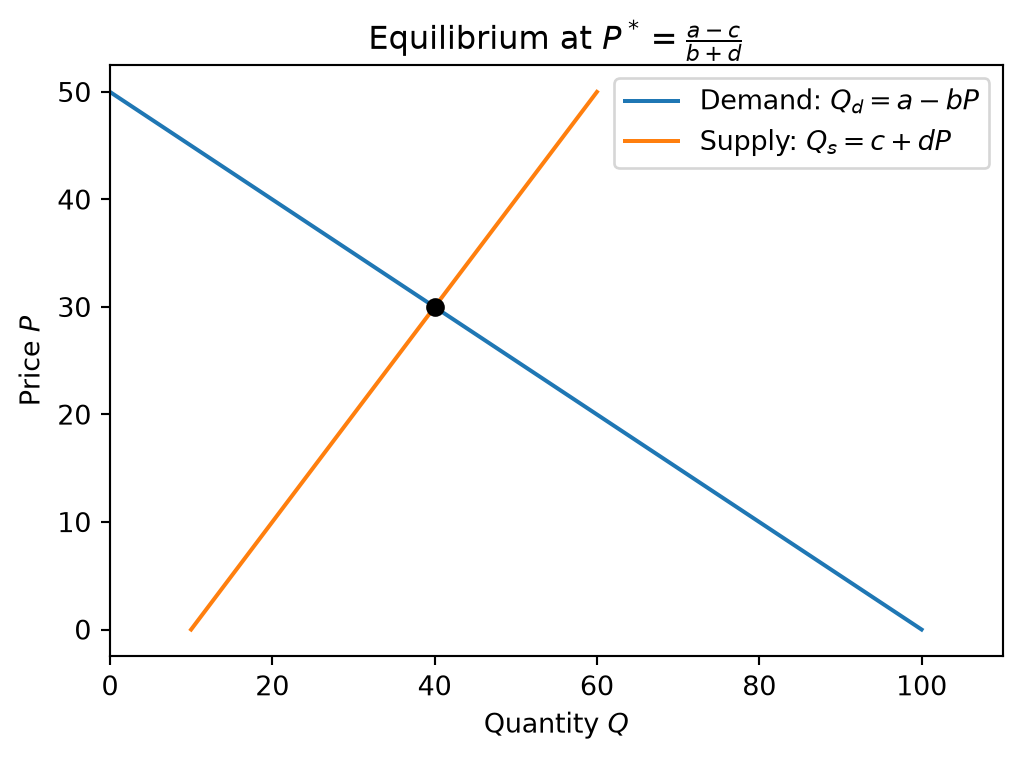

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(a - b * p, p, label=r"Demand: $Q_d = a - bP$")
ax.plot(c + d * p, p, label=r"Supply: $Q_s = c + dP$")
ax.plot(q_star, p_star, "o", color="black")
ax.set_xlabel(r"Quantity $Q$")
ax.set_ylabel(r"Price $P$")
ax.set_title(r"Equilibrium at $P^* = \frac{a - c}{b + d}$")
ax.set_xlim(0, 110)
ax.legend()
plt.show()

To put computed numbers into formatted text, build a Markdown string and display it. In an f-string, LaTeX's own braces must be doubled, `{{` and `}}`, so Python doesn't mistake them for placeholders; single braces still insert values:

In [6]:
from IPython.display import Markdown, display

display(Markdown(f"The market clears at $P^* = {p_star:.2f}$ and $Q^* = {q_star:.2f}$."))
display(Markdown(rf"Check: $\frac{{a - c}}{{b + d}} = {(a - c) / (b + d):.2f}$"))

The market clears at $P^* = 30.00$ and $Q^* = 40.00$.

Check: $\frac{a - c}{b + d} = 30.00$

### Try it

**T1.** Add a Markdown cell below this one with a short heading, a two-item bulleted list of things the competitive model leaves out, and the supply curve as inline math.

**T2.** In a second Markdown cell, write the equilibrium quantity as display math, $Q^* = a - bP^* = \frac{ad + bc}{b + d}$, and check by hand that it gives 40.

**T3.** Copy the text below into a new Markdown cell, render it, and fix it. It has one example of each mistake above. Not every editor shows all five as errors, so read it carefully, too.

```markdown
At a price of $25 the firm sells 50 units, so revenue is $1,250.
Demand is $ Q_d = a - bP $ and the elasticity is $\varepsilon = -b \frac{P}{Q$.
Total cost is $C(q) = 200 + 0.5q^2$ and a large firm produces $q^10$ units.
$$
\text{CS} = \frac{1}{2} Q^* \left( \frac{a}{b} - P^* \right)

$$
```

## This week

- Complete the [Setup guide](../setup.qmd) and PS01.
- Read *Python Programming for Economics and Finance*: [1. About These Lectures](https://python-programming.quantecon.org/about_py.html).
- Keep Quarto's [Markdown Basics](https://quarto.org/docs/authoring/markdown-basics.html) page handy. It covers everything in "Writing it up" and more.
- Bring a laptop, Chromebook, or tablet with a keyboard to the second session. We'll set up codespaces together.